# FLIR `video_*_test`: RGB ↔ IR test-set quality, 2026-10-29

Quality check of the test split behind F15 (`spec/2026-10-28-cross-modal-detector-transfer/`) and every later
test-set result (F9, F12). The two `video_*_test` splits are **time-synced recordings of the same drives** by an RGB
and a thermal camera mounted side by side (F2, F3: `rgb_to_thermal_vid_map.json` is a bijection over the 3,749 frames).
So for a pair of frames we expect:

- **the same metadata**: time of day, weather and scene tags, per-frame QA status;
- **the same objects annotated**, except near the image borders. The cameras have different fields of view
  (RGB Blackfly ≈ 55° HFOV; thermal Tau2 45° / Boson 50°) and are a few cm apart, so objects at the edge of the wider
  view have no counterpart in the narrower one.

Sections:
1. **Pairing and metadata**: is each RGB frame paired with the right IR frame, and do the pair's tags agree?
2. **Annotation agreement**:
   - (a) per-frame box counts;
   - (b) a per-video thermal → RGB registration fitted on matched boxes;
   - (c) box-by-box matching inside the shared field of view, which separates border effects from real annotation
     disagreement;
   - (d) a time-sync scan;
   - (e) the worst frames.
3. **Viewer**: pick a video, draw a random frame pair IR | RGB with boxes and metadata.

Only the raw `coco.json` / `index.json` files are read (through `irwm.data.flir`); no model is involved.

**Headline**
- **The pairing is sound.** The RGB ↔ IR map is one-to-one with equal `frame_index`, and the streams are in sync
  (2d: no lag in −6…6 frames beats lag 0 by more than 0.01 in matched share; one freeway pair cannot exclude a
  1–2 frame offset).
- **Metadata: there are no per-frame condition tags, and the video tags differ inside 2 of 8 pairs** (`day` only on
  the IR file of `00004653`, `headlight glare` only on the RGB file of `1627530658`; 2 pairs are untagged). Use the
  per-pair `PAIR_CONDITIONS` table, which gives both frames of a pair the same condition.
- **The camera shift is small for the labels.** IR sees the central ≈ 83 % of the RGB width (Tau2) or all of it
  (Boson). Only 4.3 % of RGB boxes and 1.8 % of IR boxes are border cases.
- **The two GTs do not label the same objects; each labels what its own modality shows.** Inside the shared view:
  - **Person and car mostly agree.** 5 % / 10 % of RGB persons / cars and 13 % / 11 % of IR persons / cars have no
    counterpart.
  - **62–73 % of RGB lights, signs and bikes have no IR box**, while the IR labels of these classes are almost a
    subset of the RGB ones.
  - **At night IR labels cars that RGB cannot see** (72 % and 50 % of IR cars in two night pairs).
  - **256 IR frames of `1627531624` are marked empty on purpose:** the RGB boxes on them are distant headlights that
    do not show in thermal.

  Almost every disagreement is a small (S) object.
- **Consequence:** this is R10, and it is wider than sign/light/bike. It also covers **cars and persons at night**,
  where the RGB GT is the sparser one. A cross-modal cell or a per-condition RGB vs IR comparison partly measures
  annotation density. Person + car is the right comparison, but it is not perfectly symmetric at night.

In [1]:
import json
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import Markdown, display
from matplotlib.patches import Patch, Rectangle
from PIL import Image
from scipy.optimize import linear_sum_assignment

from irwm.data.classes import CLASS_NAMES, normalised_area, size_bucket
from irwm.data.flir import FlirSplit, load_rgb_thermal_map, split_dir
from irwm.utils.paths import load_env

load_env()  # FLIR data root for FlirSplit
MODS = ["rgb", "thermal"]
MOD_LABEL = {"rgb": "RGB", "thermal": "IR"}
SPLIT = {m: FlirSplit.load(m, "test") for m in MODS}
INDEX = {m: json.loads((split_dir(m, "test") / "index.json").read_text()) for m in MODS}
VIDEO_META = {m: {v["id"]: v for v in INDEX[m]["videos"]} for m in MODS}
# FLIR category id -> name, for the ignore boxes (as irwm.data.stats reads it).
CAT_NAME = SPLIT["rgb"]._category_names


def uid(file_name):
    """Frame uid at the end of a FLIR file name, equal to index.json `datasetFrameId`."""
    return file_name.rsplit("-", 1)[1].removesuffix(".jpg")


# index.json frames (qaStatus, isEmpty, tags) keyed by uid, checked against coco.json.
FRAME_META = {m: {f["datasetFrameId"]: f for f in INDEX[m]["frames"]} for m in MODS}
for m in MODS:
    assert len(FRAME_META[m]) == len(SPLIT[m])
    for r in SPLIT[m]:
        f = FRAME_META[m][uid(r.file_name)]
        assert (f["videoMetadata"]["videoId"], f["videoMetadata"]["frameIndex"]) == (r.video_id, r.frame_index)
        assert (f["width"], f["height"]) == (r.width, r.height)

# Frame pairs (rgb record, thermal record) from the official map, in (video, frame_index) order.
BY_NAME = {m: {r.file_name.removeprefix("data/"): r for r in SPLIT[m]} for m in MODS}
RGB2IR = load_rgb_thermal_map()
PAIRS = sorted(((BY_NAME["rgb"][a], BY_NAME["thermal"][b]) for a, b in RGB2IR.items()),
               key=lambda p: (p[0].video_id, p[0].frame_index))


def prefix(m, video_id):
    """Recording id shared by the two files of a pair, e.g. '1636345164' from '1636345164_visible.zip'."""
    return VIDEO_META[m][video_id]["filename"].split("_")[0]


# Pair conditions as set in detector_transfer_results.ipynb §0 (one table per pair; three untagged choices explained
# there). Kept in sync by hand: notebooks never import each other.
PAIR_CONDITIONS = {
    "1636345164": ("night", "fog"),
    "1636345107": ("night", "fog"),
    "1627530658": ("night", "rain"),
    "1627531624": ("night", "rain"),
    "1628739688": ("night", "none"),   # untagged: dark sky, headlight glare
    "1624582918": ("dawn", "cloudy"),
    "1629771558": ("dusk", "none"),    # untagged: "near sunset", driving into the sun
    "00004653": ("day", "clear"),      # only the thermal file is tagged day; no weather tag, no glare
}
PAIR_IDS = {}  # prefix -> (rgb video_id, thermal video_id)
for r, t in PAIRS:
    PAIR_IDS.setdefault(prefix("rgb", r.video_id), (r.video_id, t.video_id))
PAIR_FRAMES = defaultdict(list)  # prefix -> [(rgb record, thermal record)] in frame order
for r, t in PAIRS:
    PAIR_FRAMES[prefix("rgb", r.video_id)].append((r, t))
ORDER = sorted(PAIR_FRAMES, key=lambda p: -len(PAIR_FRAMES[p]))  # largest pair first
print(f"{len(PAIRS)} frame pairs in {len(ORDER)} video pairs")

3749 frame pairs in 8 video pairs


In [2]:
# Plot style, as in the other notebooks: RGB blue, thermal orange. Class colours are chosen to stay visible on both
# dark thermal frames and bright RGB frames.
MOD_COLOR = {"rgb": "#2a78d6", "thermal": "#eb6834"}
INK, MUTED, GRID = "#0b0b0b", "#52514e", "#e6e5e0"
CLASS_COLOR = dict(zip(CLASS_NAMES, ["#ff3b30", "#ffcc00", "#00e5ff", "#c86bff", "#7cff4d", "#ff8ad8"]))
IGNORE_COLOR = "#bdbdbd"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#8a8984", "axes.labelcolor": MUTED, "xtick.color": MUTED,
    "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.axisbelow": True, "font.size": 9, "axes.titlesize": 10, "axes.titleweight": "bold",
    "legend.frameon": False,
})


def md_table(header, rows):
    out = ["| " + " | ".join(header) + " |", "|" + "---|" * len(header)]
    out += ["| " + " | ".join(str(v) for v in row) + " |" for row in rows]
    return "\n".join(out)


def pct(x):
    return f"{100 * x:.1f} %"

## 1. Pairing and metadata

FLIR has **no per-frame condition metadata**: `index.json` frame `tags` are empty in both test files, so time of day
and weather exist only as **video tags** (plus a free-text description). Per frame there are only `qaStatus`
(annotation review) and `isEmpty` (the annotator marked the frame as having no objects). The checks:

- the map pairs every RGB frame with exactly one IR frame, of the same video pair and the same `frame_index`;
- the two files of a pair carry the same condition tags and description;
- per frame, `qaStatus`, `isEmpty` and `tags` agree.

In [3]:
# Pairing integrity.
assert len(RGB2IR) == len(set(RGB2IR.values())) == len(SPLIT["rgb"]) == len(SPLIT["thermal"])
vid_pairs = Counter((r.video_id, t.video_id) for r, t in PAIRS)
assert len({a for a, _ in vid_pairs}) == len({b for _, b in vid_pairs}) == len(vid_pairs) == len(ORDER)
n_fi = sum(r.frame_index != t.frame_index for r, t in PAIRS)
print(f"bijection over {len(PAIRS)} frames, {len(vid_pairs)} video ↔ video pairs, frame_index mismatches: {n_fi}")
assert all(not FRAME_META[m][uid(x.file_name)]["tags"] for r, t in PAIRS for m, x in zip(MODS, (r, t)))
print("index.json frame tags: empty for every frame of both modalities")

# Tags that describe conditions; the rest are camera, format or scene tags.
COND_TAGS = {"day", "night", "dawn", "dusk", "sunset", "dark", "fog", "rain", "cloudy", "snow", "headlight glare"}
rows, frame_rows = [], []
for p in ORDER:
    vr, vt = PAIR_IDS[p]
    mr, mt = VIDEO_META["rgb"][vr], VIDEO_META["thermal"][vt]
    tr, tt = set(mr["tags"]), set(mt["tags"])
    fr = [r.frame_index for r, _ in PAIR_FRAMES[p]]
    gaps = [b - a - 1 for a, b in zip(fr, fr[1:]) if b - a > 1]
    rows.append([
        f"`{p}`", "/".join(PAIR_CONDITIONS[p]), len(fr), f"{fr[0]}–{fr[-1]}", ", ".join(map(str, gaps)) or "–",
        f"{PAIR_FRAMES[p][0][0].width}×{PAIR_FRAMES[p][0][0].height}",
        ", ".join(sorted(tr & COND_TAGS)) or "–", ", ".join(sorted(tt & COND_TAGS)) or "–",
        ", ".join(sorted((tr - tt) & COND_TAGS)) or "–", ", ".join(sorted((tt - tr) & COND_TAGS)) or "–",
        "same" if mr.get("description") == mt.get("description") else
        ("both missing" if not mr.get("description") and not mt.get("description") else "differs"),
    ])
    # Per-frame metadata of the pair.
    fm = [(FRAME_META["rgb"][uid(r.file_name)], FRAME_META["thermal"][uid(t.file_name)]) for r, t in PAIR_FRAMES[p]]
    qa = Counter((a.get("qaStatus", "–"), b.get("qaStatus", "–")) for a, b in fm)
    emp = Counter((a["isEmpty"], b["isEmpty"]) for a, b in fm)
    frame_rows.append([
        f"`{p}`", len(fm),
        ", ".join(f"{a}/{b}: {n}" for (a, b), n in sorted(qa.items())),
        sum(a.get("qaStatus") != b.get("qaStatus") for a, b in fm),
        sum(a["isEmpty"] for a, _ in fm), sum(b["isEmpty"] for _, b in fm),
        sum(a["isFlagged"] or b["isFlagged"] for a, b in fm),
    ])
display(Markdown("**Video level** (condition tags only; `only RGB` / `only IR` = tags present in one file of the pair)\n\n"
                 + md_table(["pair", "condition (§0 table)", "frames", "frame_index", "gaps", "RGB size",
                             "RGB tags", "IR tags", "only RGB", "only IR", "description"], rows)))
display(Markdown("**Frame level** (`qaStatus` RGB/IR; `–` = field absent)\n\n"
                 + md_table(["pair", "frames", "qaStatus RGB/IR", "qaStatus differs", "isEmpty RGB", "isEmpty IR",
                             "isFlagged"], frame_rows)))

bijection over 3749 frames, 8 video ↔ video pairs, frame_index mismatches: 0
index.json frame tags: empty for every frame of both modalities


**Video level** (condition tags only; `only RGB` / `only IR` = tags present in one file of the pair)

| pair | condition (§0 table) | frames | frame_index | gaps | RGB size | RGB tags | IR tags | only RGB | only IR | description |
|---|---|---|---|---|---|---|---|---|---|---|
| `1624582918` | dawn/cloudy | 1033 | 0–1479 | 270, 177 | 1024×768 | cloudy, dawn | cloudy, dawn | – | – | same |
| `1629771558` | dusk/none | 565 | 0–564 | – | 1024×768 | – | – | – | – | differs |
| `1627530658` | night/rain | 540 | 300–839 | – | 1224×1024 | dark, headlight glare, night, rain | dark, night, rain | headlight glare | – | same |
| `00004653` | day/clear | 428 | 6393–8072 | 1252 | 1224×1024 | – | day | – | day | differs |
| `1627531624` | night/rain | 411 | 99–509 | – | 1224×1024 | dark, night, rain | dark, night, rain | – | – | same |
| `1636345164` | night/fog | 338 | 745–1082 | – | 1224×1024 | fog, night | fog, night | – | – | same |
| `1628739688` | night/none | 226 | 0–225 | – | 1224×1024 | – | – | – | – | differs |
| `1636345107` | night/fog | 208 | 368–575 | – | 1224×1024 | fog, night | fog, night | – | – | same |

**Frame level** (`qaStatus` RGB/IR; `–` = field absent)

| pair | frames | qaStatus RGB/IR | qaStatus differs | isEmpty RGB | isEmpty IR | isFlagged |
|---|---|---|---|---|---|---|
| `1624582918` | 1033 | approved/approved: 1032, approved/–: 1 | 1 | 0 | 0 | 0 |
| `1629771558` | 565 | approved/approved: 565 | 0 | 0 | 0 | 0 |
| `1627530658` | 540 | approved/approved: 539, approved/–: 1 | 1 | 0 | 0 | 0 |
| `00004653` | 428 | –/–: 428 | 0 | 0 | 0 | 0 |
| `1627531624` | 411 | approved/approved: 411 | 0 | 0 | 256 | 0 |
| `1636345164` | 338 | –/–: 338 | 0 | 0 | 0 | 0 |
| `1628739688` | 226 | approved/approved: 226 | 0 | 0 | 0 | 0 |
| `1636345107` | 208 | –/–: 208 | 0 | 0 | 0 | 0 |

**Reading.**
- **The pairing is clean.** The map is a bijection, every frame pair stays inside one video pair (8 ↔ 8), and both
  frames have the same `frame_index`. Thermal is 640×512 everywhere. RGB is 1224×1024 (Blackfly with the Tau2 rig) or
  1024×768 (the two Boson pairs).
- **There is no per-frame condition metadata, and the video tags are incomplete and disagree inside 2 of 8 pairs.**
  `00004653` has `day` only on the IR file, and `1627530658` has `headlight glare` only on the RGB file. Two pairs
  (`1628739688` parking lot, `1629771558` I-205) have no time or weather tag on either file. The three differing
  descriptions differ only in the camera wording. So the condition of a frame must come from the **per-pair table**
  (`PAIR_CONDITIONS`, `detector_transfer_results.ipynb` §0), never from one file's tags. By construction, that table
  gives both frames of a pair the same condition.
- **The per-frame metadata agrees except in two places.**
  - 2 IR frames have no `qaStatus` where RGB says `approved` (one each in `1624582918` and `1627530658`). The three
    pairs without QA have none on either side.
  - **256 IR frames are marked `isEmpty`, all in pair `1627531624`, while no RGB frame is.** Section 2a looks at what
    these frames contain.

## 2. Annotation agreement

### 2a. Per-frame box counts

The simplest check: the number of boxes of each of the 6 classes on the two frames of a pair. It ignores geometry, so
objects at the border of the wider camera count as disagreements here; 2c removes them.

**Kept boxes per class over all 3,749 pairs**

| class | RGB boxes | IR boxes | IR / RGB | frames equal | frames within ±1 | only RGB has the class | only IR has the class |
|---|---|---|---|---|---|---|---|
| person | 11278 | 12323 | 1.09 | 70.8 % | 88.7 % | 0.1 % | 0.0 % |
| bike | 446 | 113 | 0.25 | 94.1 % | 97.3 % | 4.0 % | 0.0 % |
| car | 30893 | 30517 | 0.99 | 29.9 % | 59.5 % | 6.8 % | 3.6 % |
| motor | 3573 | 3314 | 0.93 | 90.2 % | 97.0 % | 0.4 % | 0.1 % |
| light | 17818 | 6758 | 0.38 | 61.8 % | 62.0 % | 7.7 % | 0.0 % |
| sign | 17213 | 5660 | 0.33 | 41.7 % | 60.3 % | 22.3 % | 1.3 % |

**Frames empty in one modality but annotated in the other**

| pair | case | frames | of the pair | frame_index runs (length) | kept boxes without counterpart |
|---|---|---|---|---|---|
| `1627531624` | IR empty, RGB annotated | 256 | 62% | 99–277 (179), 376–452 (77) | 411 |

1627531624: RGB boxes on the empty IR frames: 411, S 100%, median normalised area 133 px² (≈ 12 px side at 640×512)
1627531624: RGB boxes on the other frames: 310, S 81%, median normalised area 267 px² (≈ 16 px side at 640×512)


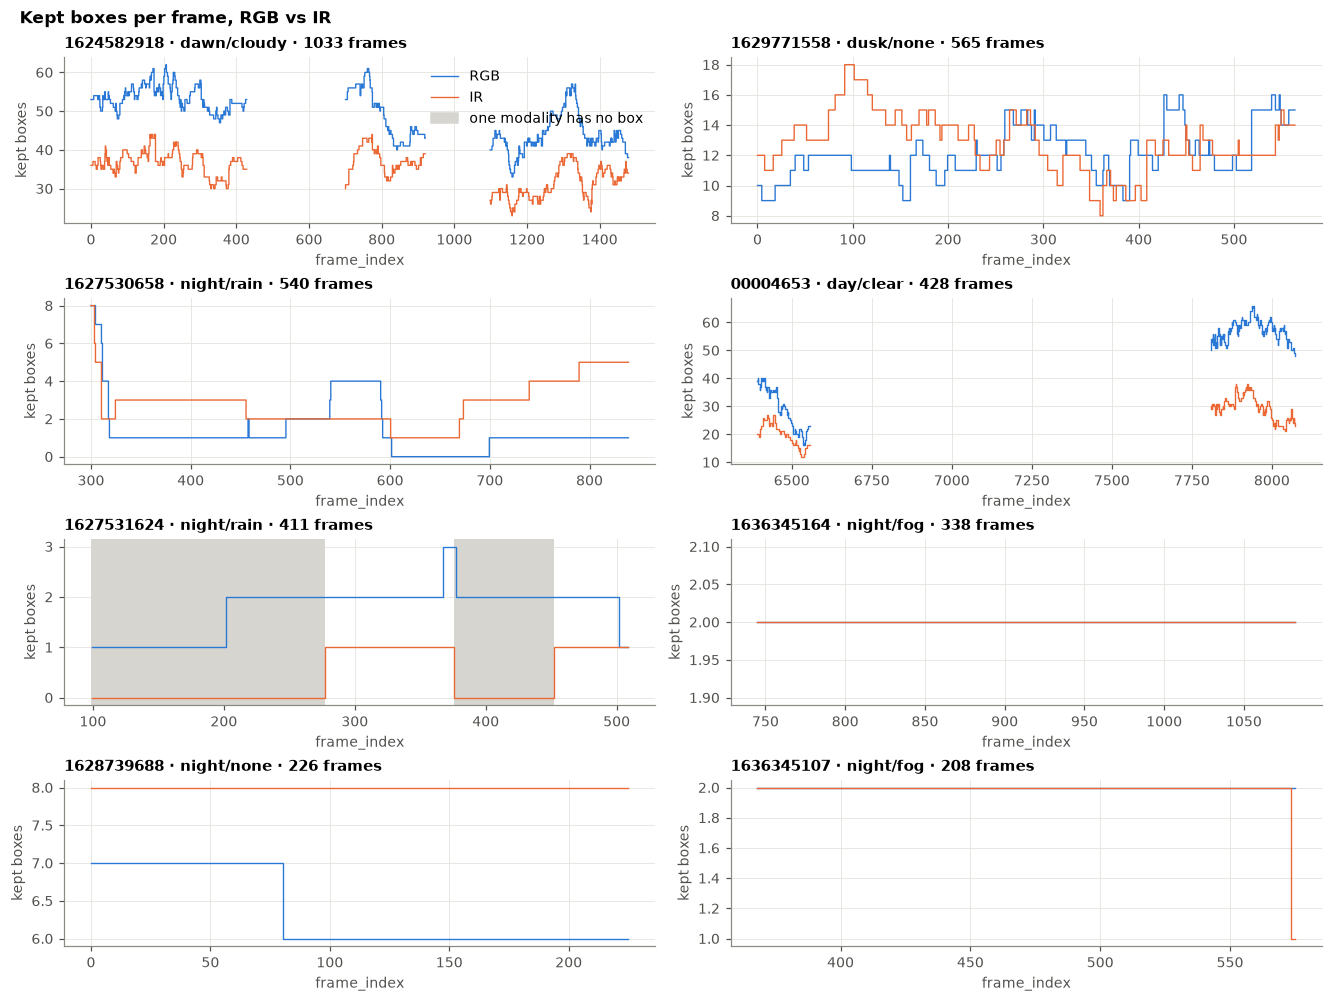

In [4]:
def n_boxes(x):
    return len(x.labels) + len(x.ignore_boxes)


count_rows = []
for c, name in enumerate(CLASS_NAMES):
    a = np.array([(r.labels == c).sum() for r, _ in PAIRS])
    b = np.array([(t.labels == c).sum() for _, t in PAIRS])
    count_rows.append([name, a.sum(), b.sum(), f"{b.sum() / a.sum():.2f}", pct((a == b).mean()),
                       pct((np.abs(a - b) <= 1).mean()), pct(((a > 0) & (b == 0)).mean()),
                       pct(((b > 0) & (a == 0)).mean())])
display(Markdown("**Kept boxes per class over all 3,749 pairs**\n\n" + md_table(
    ["class", "RGB boxes", "IR boxes", "IR / RGB", "frames equal", "frames within ±1", "only RGB has the class",
     "only IR has the class"], count_rows)))


def runs(frames):
    """Contiguous frame_index runs, as 'a–b (n)'."""
    out, start = [], 0
    for i in range(1, len(frames) + 1):
        if i == len(frames) or frames[i] != frames[i - 1] + 1:
            out.append(f"{frames[start]}–{frames[i - 1]} ({i - start})")
            start = i
    return ", ".join(out)


# Frames annotated in one modality and completely empty (no kept or ignore box) in the other.
EMPTY_SIDE = {}  # (rgb image_id) -> modality whose frame has no box
gap_rows = []
for p in ORDER:
    for m, other in [("thermal", "rgb"), ("rgb", "thermal")]:
        fr = [r.frame_index for r, t in PAIR_FRAMES[p]
              if n_boxes(dict(rgb=r, thermal=t)[m]) == 0 and n_boxes(dict(rgb=r, thermal=t)[other]) > 0]
        for r, t in PAIR_FRAMES[p]:
            if n_boxes(dict(rgb=r, thermal=t)[m]) == 0 and n_boxes(dict(rgb=r, thermal=t)[other]) > 0:
                EMPTY_SIDE[r.image_id] = m
        if fr:
            lost = sum(len(dict(rgb=r, thermal=t)[other].labels) for r, t in PAIR_FRAMES[p]
                       if EMPTY_SIDE.get(r.image_id) == m)
            gap_rows.append([f"`{p}`", f"{MOD_LABEL[m]} empty, {MOD_LABEL[other]} annotated", len(fr),
                             f"{len(fr) / len(PAIR_FRAMES[p]):.0%}", runs(fr), lost])
display(Markdown("**Frames empty in one modality but annotated in the other**\n\n" + md_table(
    ["pair", "case", "frames", "of the pair", "frame_index runs (length)", "kept boxes without counterpart"],
    gap_rows)))

# The boxes the empty frames miss: size of the RGB boxes on them vs on the rest of the same pair.
for p in {p for p in ORDER for r, _ in PAIR_FRAMES[p] if r.image_id in EMPTY_SIDE}:
    for name, sel in [("on the empty IR frames", True), ("on the other frames", False)]:
        sizes = [size_bucket(normalised_area(b[2], b[3], r.width, r.height))
                 for r, _ in PAIR_FRAMES[p] if (r.image_id in EMPTY_SIDE) == sel for b in r.boxes]
        a = [normalised_area(b[2], b[3], r.width, r.height)
             for r, _ in PAIR_FRAMES[p] if (r.image_id in EMPTY_SIDE) == sel for b in r.boxes]
        print(f"{p}: RGB boxes {name}: {len(a)}, S {Counter(sizes)['S'] / len(a):.0%}, "
              f"median normalised area {np.median(a):.0f} px² (≈ {np.sqrt(np.median(a)):.0f} px side at 640×512)")

# Timeline: kept boxes per frame, RGB vs IR, one panel per pair; grey = frames with no box in one modality.
fig, axes = plt.subplots(4, 2, figsize=(12, 9), constrained_layout=True)
for ax, p in zip(axes.flat, ORDER):
    fr = np.array([r.frame_index for r, _ in PAIR_FRAMES[p]], dtype=float)
    brk = np.flatnonzero(np.diff(fr) > 1) + 1  # frame_index gaps: break the line instead of bridging them
    for m, k in [("rgb", 0), ("thermal", 1)]:
        y = np.array([len(pair[k].labels) for pair in PAIR_FRAMES[p]], dtype=float)
        ax.plot(np.insert(fr, brk, np.nan), np.insert(y, brk, np.nan), lw=0.9, color=MOD_COLOR[m],
                drawstyle="steps-mid", label=MOD_LABEL[m])
    for r, _ in PAIR_FRAMES[p]:
        if r.image_id in EMPTY_SIDE:
            ax.axvspan(r.frame_index - 0.5, r.frame_index + 0.5, color="#d6d5d0", lw=0)
    ax.set_title(f"{p} · {'/'.join(PAIR_CONDITIONS[p])} · {len(fr)} frames", loc="left")
    ax.set_xlabel("frame_index")
    ax.set_ylabel("kept boxes")
axes[0, 0].legend(handles=[*axes[0, 0].get_lines()[:2], Patch(color="#d6d5d0", label="one modality has no box")],
                  loc="upper right")
fig.suptitle("Kept boxes per frame, RGB vs IR", x=0.01, ha="left", fontweight="bold")
plt.show()

**Reading.**
- **One block of empty IR frames: pair `1627531624` (night, rain), IR frames 99–277 and 376–452 (256 of 411, 62 %)**
  have no box at all, while RGB has 1–3 boxes on each. These are the 256 `isEmpty` frames of §1.
- **The empty frames are an annotator's decision, not lost annotations.** The 411 RGB boxes on them are all S, with a
  median normalised area of 133 px² (≈ 12 px side), against 81 % S and 267 px² on the rest of the pair. In the viewer
  (`VIDEO = "1627531624"`, e.g. `FRAME_INDEX = 250`), they are oncoming cars **seen only as distant headlights**: bright
  in RGB, invisible in thermal at that range. From frame 278 on, the IR annotator labels the same car once it is close
  enough to show in thermal. The frames are flagged `isEmpty` on purpose, which matches what the thermal image shows.
  Each modality's GT labels what is visible in that modality.
- **Person, car and motor agree in total** (IR/RGB 1.09, 0.99, 0.93), but per frame the counts are equal in only 30 %
  of frames for car and 71 % for person. A one-box offset is common, so per-frame counts cannot separate border
  effects from annotation differences. 2c does that.
- **Sign, light and bike are 2.6–4× rarer in IR** (0.33, 0.38, 0.25; R10, F2).

### 2b. Registration: thermal → RGB

To compare box by box, map thermal boxes into the RGB frame. The two cameras are fixed side by side with parallel
axes, so per video pair the map is a **similarity in pixels**: one scale `s` (the ratio of the cameras' angular
pixel sizes) and an offset per axis. Lens distortion is ignored, and so is parallax: a few cm of baseline is
negligible for objects beyond a few metres. In coordinates normalised by the frame size it reads
`x_rgb = a_x · x_ir + b_x`, `y_rgb = a_y · y_ir + b_y`, with `a_y = a_x · (H_ir / H_rgb) / (W_ir / W_rgb)` fixed by the
frame sizes.

The constraint matters. Person and car centres mostly lie in a narrow band around the horizon (`y-range` in the
table), so a free fit of `a_y` is poorly conditioned. The table shows both: the fitted `a_y/a_x` (`free a_y/a_x`) next
to the value that square pixels imply.

**Fit:** person and car only (the reliable classes). Hungarian matching of box centres with a shrinking gate (20 % →
3 % of the frame), then trimmed least squares, starting from the identity.

In [5]:
def ncent(boxes, x):
    """COCO xywh in px -> [N, 4] (cx, cy, w, h) normalised by the frame size of record x."""
    b = np.asarray(boxes, dtype=float).reshape(-1, 4)
    s = np.array([x.width, x.height] * 2, dtype=float)
    return np.c_[b[:, :2] + b[:, 2:] / 2, b[:, 2:]] / s


def to_rgb(P, c):
    """Thermal (cx, cy, w, h) normalised -> RGB normalised, with P = (a_x, b_x, a_y, b_y)."""
    return np.c_[P[0] * c[:, 0] + P[1], P[2] * c[:, 1] + P[3], P[0] * c[:, 2], P[2] * c[:, 3]]


FIT_CLASSES = (CLASS_NAMES.index("person"), CLASS_NAMES.index("car"))


def aspect_k(r, t):
    """a_y / a_x of a square-pixel similarity between thermal frame t and RGB frame r."""
    return (t.height / r.height) / (t.width / r.width)


def lstsq_map(X, Y, k=None):
    """Least-squares P = (a_x, b_x, a_y, b_y) from matched centres X (IR) -> Y (RGB); a_y = k · a_x unless k is None."""
    if k is None:  # free fit, one line per axis
        (ax_, bx), (ay, by) = np.polyfit(X[:, 0], Y[:, 0], 1), np.polyfit(X[:, 1], Y[:, 1], 1)
        return np.array([ax_, bx, ay, by])
    A = np.zeros((2 * len(X), 3))
    A[0::2, 0], A[0::2, 1], A[1::2, 0], A[1::2, 2] = X[:, 0], 1, k * X[:, 1], 1
    a, bx, by = np.linalg.lstsq(A, Y[:, :2].ravel(), rcond=None)[0]
    return np.array([a, bx, k * a, by])


def fit_mapping(pairs, P0=None, gates=(0.2, 0.1, 0.05, 0.03), free=False):
    """Fit P on frame pairs [(rgb, thermal)] of one video pair.

    Returns (P, n matched boxes, median residual in RGB-normalised units, (y min, y max) of the matched IR centres).
    """
    P = np.array([1.0, 0.0, 1.0, 0.0]) if P0 is None else np.asarray(P0, dtype=float)
    k = None if free else aspect_k(*pairs[0])
    res = np.array([np.nan])
    for gate in gates:
        X, Y = [], []
        for r, t in pairs:
            cr, ct = ncent(r.boxes, r), to_rgb(P, ncent(t.boxes, t))
            for c in FIT_CLASSES:
                i, j = np.flatnonzero(r.labels == c), np.flatnonzero(t.labels == c)
                if not len(i) or not len(j):
                    continue
                d = np.linalg.norm(cr[i, None, :2] - ct[None, j, :2], axis=-1)
                a, b = linear_sum_assignment(d)
                ok = d[a, b] < gate
                X.append(ncent(t.boxes, t)[j[b[ok]]])
                Y.append(cr[i[a[ok]]])
        X, Y = np.concatenate(X or [np.zeros((0, 4))]), np.concatenate(Y or [np.zeros((0, 4))])
        if len(X) < 10:
            return P, len(X), np.nan, (np.nan, np.nan)
        for _ in range(3):  # trimmed least squares: drop residuals > 3x the median, refit
            P = lstsq_map(X, Y, k)
            res = np.linalg.norm(to_rgb(P, X)[:, :2] - Y[:, :2], axis=1)
            keep = res <= 3 * np.median(res)
            X, Y = X[keep], Y[keep]
    return P, len(X), float(np.median(res)), (float(X[:, 1].min()), float(X[:, 1].max()))


MAP = {p: fit_mapping(PAIR_FRAMES[p]) for p in ORDER}
FREE = {p: fit_mapping(PAIR_FRAMES[p], free=True) for p in ORDER}

rows = []
for p in ORDER:
    P, n, res, (y0, y1) = MAP[p]
    r0, t0 = PAIR_FRAMES[p][0]
    Pf = FREE[p][0]
    rows.append([f"`{p}`", f"{t0.width}×{t0.height} → {r0.width}×{r0.height}", n, f"{y0:.2f}–{y1:.2f}",
                 f"{P[0]:.3f}", f"{P[1]:+.3f}", f"{P[2]:.3f}", f"{P[3]:+.3f}", f"{res * 1000:.1f}",
                 f"{res * r0.width:.1f}", f"{aspect_k(r0, t0):.3f}", f"{Pf[2] / Pf[0]:.3f}"])
display(Markdown(
    "**Per-pair map** (thermal → RGB, normalised coordinates). The IR view inside the RGB frame is x ∈ [b_x, a_x + b_x], "
    "y ∈ [b_y, a_y + b_y]. The residual is the median distance of matched centres, in ‰ of the RGB frame and in RGB px. "
    "`y-range` is the vertical span of the matched IR centres.\n\n" + md_table(
        ["pair", "IR → RGB px", "matched boxes", "y-range", "a_x", "b_x", "a_y", "b_y", "residual ‰", "≈ RGB px",
         "a_y/a_x (square px)", "free a_y/a_x"], rows)))

**Per-pair map** (thermal → RGB, normalised coordinates). The IR view inside the RGB frame is x ∈ [b_x, a_x + b_x], y ∈ [b_y, a_y + b_y]. The residual is the median distance of matched centres, in ‰ of the RGB frame and in RGB px. `y-range` is the vertical span of the matched IR centres.

| pair | IR → RGB px | matched boxes | y-range | a_x | b_x | a_y | b_y | residual ‰ | ≈ RGB px | a_y/a_x (square px) | free a_y/a_x |
|---|---|---|---|---|---|---|---|---|---|---|---|
| `1624582918` | 640×512 → 1024×768 | 19474 | 0.34–0.59 | 0.990 | -0.007 | 1.056 | +0.001 | 4.9 | 5.0 | 1.067 | 1.063 |
| `1629771558` | 640×512 → 1024×768 | 5121 | 0.34–0.52 | 0.994 | -0.014 | 1.060 | +0.002 | 5.0 | 5.1 | 1.067 | 0.769 |
| `1627530658` | 640×512 → 1224×1024 | 292 | 0.61–0.68 | 0.869 | +0.045 | 0.831 | +0.057 | 5.2 | 6.4 | 0.956 | 0.723 |
| `00004653` | 640×512 → 1224×1024 | 4825 | 0.39–0.58 | 0.834 | +0.065 | 0.797 | +0.082 | 1.9 | 2.3 | 0.956 | 0.949 |
| `1627531624` | 640×512 → 1224×1024 | 132 | 0.62–0.70 | 0.851 | +0.051 | 0.814 | +0.068 | 4.1 | 5.1 | 0.956 | 0.739 |
| `1636345164` | 640×512 → 1224×1024 | 666 | 0.44–0.49 | 0.817 | +0.083 | 0.781 | +0.105 | 6.8 | 8.3 | 0.956 | 0.952 |
| `1628739688` | 640×512 → 1224×1024 | 985 | 0.58–0.62 | 0.835 | +0.056 | 0.799 | +0.078 | 4.7 | 5.8 | 0.956 | 0.958 |
| `1636345107` | 640×512 → 1224×1024 | 389 | 0.44–0.53 | 0.827 | +0.080 | 0.791 | +0.103 | 4.5 | 5.5 | 0.956 | 0.857 |

**Reading.**
- **The registration is tight.** The median residual of matched person/car centres is 1.9–6.8 ‰ of the RGB frame
  (2–8 RGB px), so a box-level comparison is meaningful even for small objects.
- **The square-pixel constraint holds where it can be tested.** In the four pairs whose matched boxes span enough
  height, the free fit gives `a_y/a_x` within 1 % of the square-pixel value: `1624582918` 1.063 vs 1.067, `00004653`
  0.949 vs 0.956, `1636345164` 0.952, `1628739688` 0.958. Where all boxes sit in a band a few % high, the free fit
  drifts to 0.72–0.86 (`1627530658`, `1627531624`, `1629771558`, `1636345107`). This is the poorly conditioned case
  that the constraint removes.
- **The camera shift is the one expected, and it is moderate.**
  - Tau2 pairs (1224×1024 RGB): IR covers the central 82–87 % of the RGB width and 78–83 % of its height.
  - Boson pairs (`1624582918`, `1629771558`, 1024×768 RGB): `a_x ≈ 0.99`, so IR covers the full RGB width and
    slightly more than its height.
  - The RGB strip outside the IR view holds few labelled objects, because most objects sit near the centre (2c: 4.3 %
    of RGB boxes and 1.8 % of IR boxes are `border`).

### 2c. Box-by-box matching inside the shared field of view

Each kept box of each frame pair gets one status, in this order of priority:

| status | meaning |
|---|---|
| `empty frame` | the other modality's frame has no box at all (the 2a gap) |
| `matched` | a box of the **same class** in the other modality with IoU ≥ 0.3 after mapping (Hungarian, one-to-one) |
| `class swap` | no same-class match, but an unmatched box of **another class** (or an ignore box: truck, bus, …) overlaps it with IoU ≥ 0.3 |
| `border` | the box reaches the edge of the **shared view** (IR view ∩ RGB frame), within 2 % of the RGB frame, or lies outside it: one camera sees the object cut or not at all |
| `missing` | inside the shared view, no counterpart at all: **annotation disagreement** |

**Overlap with a tolerance.** Before the IoU, every box is grown by 1 % of the frame on each side (≈ 6 IR px, ≈ 12 RGB
px). Most boxes are small (R3), and a 10-px light shifted by the 2b residual plus the two annotators' own box jitter
fails a plain IoU ≥ 0.3 although it is clearly the same object. Growing barely changes the IoU of large boxes. The
grid below the tables shows how the matched share depends on the padding and the threshold.

`missing` is the number that matters: an object inside the shared view that only one modality's annotator labelled.
Its size bucket uses the 640×512-normalised area (TechStack §3.4).

In [6]:
IOU_MATCH, BOX_PAD, BORDER = 0.3, 0.01, 0.02
STATUSES = ["matched", "class swap", "border", "missing", "empty frame"]


def xyxy(c):
    return np.c_[c[:, :2] - c[:, 2:] / 2, c[:, :2] + c[:, 2:] / 2]


def iou(a, b):
    """[N, 4] x [M, 4] xyxy -> [N, M]."""
    if not len(a) or not len(b):
        return np.zeros((len(a), len(b)))
    lt = np.maximum(a[:, None, :2], b[None, :, :2])
    rb = np.minimum(a[:, None, 2:], b[None, :, 2:])
    inter = np.prod(np.clip(rb - lt, 0, None), axis=-1)
    area = lambda x: np.prod(x[:, 2:] - x[:, :2], axis=-1)  # noqa: E731
    return inter / (area(a)[:, None] + area(b)[None] - inter)


def compare_pair(r, t, P, iou_match=IOU_MATCH, pad=BOX_PAD):
    """Status of every kept box of r (rgb) and t (thermal): (array[str] for r.boxes, array[str] for t.boxes).

    Overlaps are IoUs of boxes in RGB-normalised coordinates, each grown by `pad` on every side.
    """
    grow = np.array([-pad, -pad, pad, pad])
    br, bt = xyxy(ncent(r.boxes, r)) + grow, xyxy(to_rgb(P, ncent(t.boxes, t))) + grow
    gr, gt = xyxy(ncent(r.ignore_boxes, r)) + grow, xyxy(to_rgb(P, ncent(t.ignore_boxes, t))) + grow
    st = {"rgb": np.full(len(br), "missing", dtype=object), "thermal": np.full(len(bt), "missing", dtype=object)}
    if n_boxes(t) == 0 or n_boxes(r) == 0:
        st["rgb" if n_boxes(t) == 0 else "thermal"][:] = "empty frame"
        return st["rgb"], st["thermal"]
    # Same-class one-to-one matches.
    for c in range(len(CLASS_NAMES)):
        i, j = np.flatnonzero(r.labels == c), np.flatnonzero(t.labels == c)
        m = iou(br[i], bt[j])
        if m.size:
            a, b = linear_sum_assignment(-m)
            k = m[a, b] >= iou_match
            st["rgb"][i[a[k]]] = "matched"
            st["thermal"][j[b[k]]] = "matched"
    # Class swaps: an unmatched box overlapping an unmatched other-class box or an ignore box of the other modality.
    ur, ut = st["rgb"] == "missing", st["thermal"] == "missing"
    cross = iou(br, bt) * (r.labels[:, None] != t.labels[None, :]) * ur[:, None] * ut[None, :]
    swap_r = (cross.max(1, initial=0) >= iou_match) | (iou(br, gt).max(1, initial=0) >= iou_match)
    swap_t = (cross.max(0, initial=0) >= iou_match) | (iou(bt, gr).max(1, initial=0) >= iou_match)
    st["rgb"][ur & swap_r] = "class swap"
    st["thermal"][ut & swap_t] = "class swap"
    # Border: the (unpadded) box reaches within BORDER of the edge of the shared view (IR view ∩ RGB frame, in
    # RGB-normalised coords) or beyond it, so one camera sees it cut or not at all.
    shared = np.r_[np.maximum([P[1], P[3]], 0), np.minimum([P[0] + P[1], P[2] + P[3]], 1)]
    for m, b in [("rgb", br - grow), ("thermal", bt - grow)]:
        out = (b[:, :2] < shared[:2] + BORDER).any(1) | (b[:, 2:] > shared[2:] - BORDER).any(1)
        st[m][(st[m] == "missing") & out] = "border"
    return st["rgb"], st["thermal"]


STATUS = {}  # (modality, image_id) -> status per kept box
for p in ORDER:
    for r, t in PAIR_FRAMES[p]:
        STATUS["rgb", r.image_id], STATUS["thermal", t.image_id] = compare_pair(r, t, MAP[p][0])


def boxes_table():
    """Long table of every kept box: one dict per box with modality, pair, class, size bucket and status."""
    out = []
    for p in ORDER:
        for r, t in PAIR_FRAMES[p]:
            for m, x in [("rgb", r), ("thermal", t)]:
                for b, lab, s in zip(x.boxes, x.labels, STATUS[m, x.image_id]):
                    out.append(dict(m=m, pair=p, cls=CLASS_NAMES[lab], status=s,
                                    size=size_bucket(normalised_area(b[2], b[3], x.width, x.height))))
    return out


BOXES = boxes_table()


def status_rows(m, key):
    rows = []
    for k in key:
        sel = [b for b in BOXES if b["m"] == m and (b["cls"] == k or k == "all")]
        cnt = Counter(b["status"] for b in sel)
        inside = len(sel) - cnt["border"] - cnt["empty frame"]
        rows.append([k, len(sel)] + [pct(cnt[s] / len(sel)) for s in STATUSES]
                    + [pct(cnt["missing"] / inside) if inside else "–"])
    return rows


for m in MODS:
    other = MOD_LABEL["thermal" if m == "rgb" else "rgb"]
    display(Markdown(f"**{MOD_LABEL[m]} boxes: status against {other}** (`missing ÷ shared view` = missing among boxes "
                     f"that are neither `border` nor `empty frame`)\n\n" + md_table(
                         ["class", "boxes", *STATUSES, "missing ÷ shared view"],
                         status_rows(m, ["all", *CLASS_NAMES]))))

# Sensitivity: matched share of kept boxes (both modalities, every 3rd frame) by box padding x IoU threshold.
grid_rows = []
for sel_name, classes in [("person + car", FIT_CLASSES), ("all 6 classes", range(len(CLASS_NAMES)))]:
    for pad in (0.0, 0.005, 0.01, 0.02):
        row = [sel_name, f"{pad:.1%}"]
        for thr in (0.1, 0.3, 0.5):
            n_m = n = 0
            for p in ORDER:
                for r, t in PAIR_FRAMES[p][::3]:
                    a, b = compare_pair(r, t, MAP[p][0], iou_match=thr, pad=pad)
                    sr, st_ = np.isin(r.labels, list(classes)), np.isin(t.labels, list(classes))
                    n_m += (a[sr] == "matched").sum() + (b[st_] == "matched").sum()
                    n += sr.sum() + st_.sum()
            row.append(pct(n_m / n))
        grid_rows.append(row)
display(Markdown("**Matched share by box padding and IoU threshold** (used: 1 %, IoU ≥ 0.3)\n\n"
                 + md_table(["classes", "padding", "IoU ≥ 0.1", "IoU ≥ 0.3", "IoU ≥ 0.5"], grid_rows)))

**RGB boxes: status against IR** (`missing ÷ shared view` = missing among boxes that are neither `border` nor `empty frame`)

| class | boxes | matched | class swap | border | missing | empty frame | missing ÷ shared view |
|---|---|---|---|---|---|---|---|
| all | 81221 | 62.6 % | 0.3 % | 4.3 % | 32.3 % | 0.5 % | 33.9 % |
| person | 11278 | 91.5 % | 0.0 % | 3.3 % | 5.2 % | 0.0 % | 5.3 % |
| bike | 446 | 24.7 % | 0.0 % | 8.7 % | 66.6 % | 0.0 % | 73.0 % |
| car | 30893 | 85.2 % | 0.6 % | 3.9 % | 9.5 % | 0.8 % | 9.9 % |
| motor | 3573 | 88.0 % | 1.7 % | 1.0 % | 9.3 % | 0.0 % | 9.4 % |
| light | 17818 | 36.2 % | 0.0 % | 3.5 % | 60.3 % | 0.0 % | 62.4 % |
| sign | 17213 | 25.9 % | 0.2 % | 7.2 % | 65.9 % | 0.9 % | 71.6 % |

**IR boxes: status against RGB** (`missing ÷ shared view` = missing among boxes that are neither `border` nor `empty frame`)

| class | boxes | matched | class swap | border | missing | empty frame | missing ÷ shared view |
|---|---|---|---|---|---|---|---|
| all | 58685 | 86.6 % | 0.7 % | 1.8 % | 10.9 % | 0.0 % | 11.1 % |
| person | 12323 | 83.7 % | 0.7 % | 2.4 % | 13.2 % | 0.0 % | 13.5 % |
| bike | 113 | 97.3 % | 0.0 % | 0.9 % | 1.8 % | 0.0 % | 1.8 % |
| car | 30517 | 86.3 % | 1.0 % | 1.7 % | 11.1 % | 0.0 % | 11.3 % |
| motor | 3314 | 94.9 % | 0.1 % | 0.9 % | 4.1 % | 0.0 % | 4.2 % |
| light | 6758 | 95.5 % | 0.5 % | 0.7 % | 3.3 % | 0.0 % | 3.3 % |
| sign | 5660 | 78.8 % | 0.1 % | 3.1 % | 18.0 % | 0.0 % | 18.6 % |

**Matched share by box padding and IoU threshold** (used: 1 %, IoU ≥ 0.3)

| classes | padding | IoU ≥ 0.1 | IoU ≥ 0.3 | IoU ≥ 0.5 |
|---|---|---|---|---|
| person + car | 0.0% | 85.5 % | 77.5 % | 61.3 % |
| person + car | 0.5% | 87.5 % | 84.2 % | 75.8 % |
| person + car | 1.0% | 88.0 % | 86.2 % | 80.6 % |
| person + car | 2.0% | 88.4 % | 87.9 % | 84.9 % |
| all 6 classes | 0.0% | 71.6 % | 64.6 % | 49.7 % |
| all 6 classes | 0.5% | 73.8 % | 70.5 % | 63.0 % |
| all 6 classes | 1.0% | 74.4 % | 72.7 % | 67.4 % |
| all 6 classes | 2.0% | 74.8 % | 74.3 % | 71.3 % |

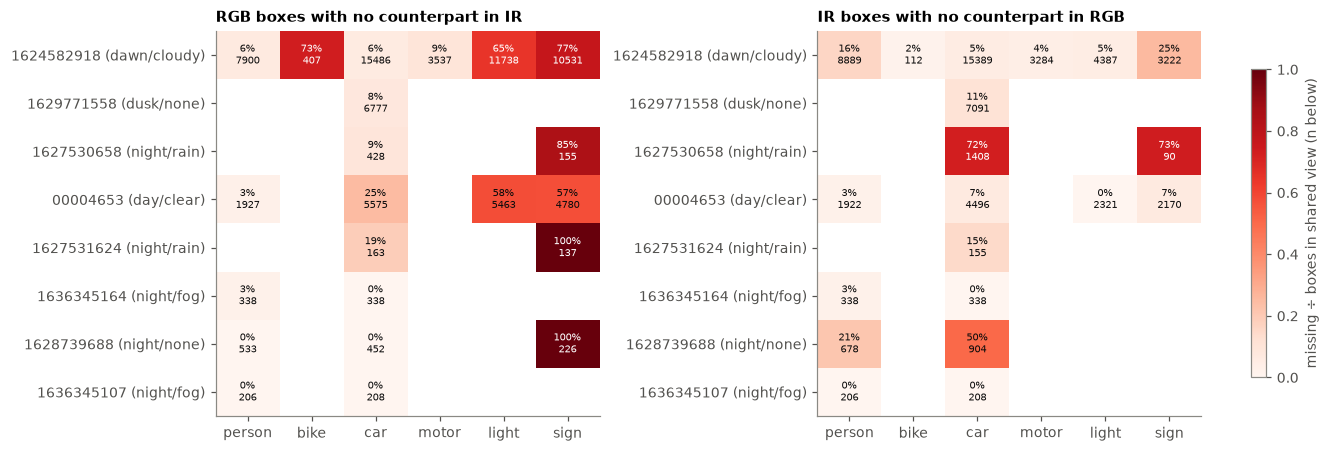

**Missing rate inside the shared view by size bucket** (640×512-normalised; n in brackets)

| boxes of | class | S | M | L |
|---|---|---|---|---|
| RGB | all | 38% (69172) | 3% (6780) | 0% (1353) |
| RGB | person | 6% (9906) | 0% (997) | 0% (1) |
| RGB | bike | 80% (355) | 25% (52) | – |
| RGB | car | 12% (24067) | 1% (4279) | 0% (1081) |
| RGB | motor | 13% (2043) | 6% (1223) | 0% (271) |
| RGB | light | 62% (17201) | – | – |
| RGB | sign | 72% (15600) | 24% (229) | – |
| IR | all | 13% (49589) | 0% (6808) | 0% (1211) |
| IR | person | 15% (10891) | 1% (1142) | – |
| IR | bike | 3% (74) | 0% (38) | – |
| IR | car | 14% (24592) | 0% (4300) | 0% (1097) |
| IR | motor | 7% (1960) | 1% (1210) | 0% (114) |
| IR | light | 3% (6707) | 0% (1) | – |
| IR | sign | 19% (5365) | 0% (117) | – |

In [7]:
# Where is the disagreement? Missing rate inside the shared view, per pair x class, for both directions; and by size.
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
for ax, m in zip(axes, MODS):
    M = np.full((len(ORDER), len(CLASS_NAMES)), np.nan)
    N = np.zeros_like(M, dtype=int)
    for i, p in enumerate(ORDER):
        for j, c in enumerate(CLASS_NAMES):
            sel = [b["status"] for b in BOXES if b["m"] == m and b["pair"] == p and b["cls"] == c
                   and b["status"] not in ("border", "empty frame")]
            N[i, j] = len(sel)
            if sel:
                M[i, j] = sel.count("missing") / len(sel)
    im = ax.imshow(M, cmap="Reds", vmin=0, vmax=1, aspect="auto")
    for i in range(M.shape[0]):
        for j in range(M.shape[1]):
            if N[i, j]:
                ax.text(j, i, f"{M[i, j]:.0%}\n{N[i, j]}", ha="center", va="center", fontsize=6.5,
                        color="white" if M[i, j] > 0.6 else INK)
    ax.set_xticks(range(len(CLASS_NAMES)), CLASS_NAMES)
    ax.set_yticks(range(len(ORDER)), [f"{p} ({'/'.join(PAIR_CONDITIONS[p])})" for p in ORDER])
    ax.grid(False)
    other = MOD_LABEL["thermal" if m == "rgb" else "rgb"]
    ax.set_title(f"{MOD_LABEL[m]} boxes with no counterpart in {other}", loc="left")
fig.colorbar(im, ax=axes, shrink=0.8, label="missing ÷ boxes in shared view (n below)")
plt.show()

size_rows = []
for m in MODS:
    for c in ["all", *CLASS_NAMES]:
        row = [MOD_LABEL[m], c]
        for s in "SML":
            sel = [b["status"] for b in BOXES if b["m"] == m and (b["cls"] == c or c == "all") and b["size"] == s
                   and b["status"] not in ("border", "empty frame")]
            row.append(f"{sel.count('missing') / len(sel):.0%} ({len(sel)})" if sel else "–")
        size_rows.append(row)
display(Markdown("**Missing rate inside the shared view by size bucket** (640×512-normalised; n in brackets)\n\n"
                 + md_table(["boxes of", "class", "S", "M", "L"], size_rows)))

**Reading** (numbers from the tables above).
- **The disagreement is not tolerance noise.** The person + car matched share rises from 77.5 % to 86.2 % when the
  boxes are grown by 1 %, then only to 87.9 % at 2 %. The remaining ≈ 12 % are boxes with no counterpart, not
  near-misses. Class swaps are rare (0.3 % of RGB and 0.7 % of IR boxes).
- **Person and car mostly agree.** Inside the shared view:
  - **RGB → IR:** 5 % of RGB persons and 10 % of RGB cars have no IR box.
  - **IR → RGB:** 13 % of IR persons and 11 % of IR cars have no RGB box.

  Where they disagree, the heat map shows that it follows **visibility in each modality**:
  - **Night: IR labels what RGB cannot see.** 72 % of IR cars in `1627530658` (night, rain: 1,408 IR vs 428 RGB car
    boxes in the shared view) and 50 % of IR cars and 21 % of IR persons in `1628739688` (night, headlight glare) have no RGB box. The RGB
    frame is dark or blinded by glare there (viewer: `1628739688`, `FRAME_INDEX = 100`).
  - **Distant pedestrians:** 16 % of IR persons in `1624582918` have no RGB box. They are small (median 88 px² against
    168 px² for matched persons), and warm bodies stand out in thermal (viewer: `1624582918`, `FRAME_INDEX = 1145`).
  - **Day:** 25 % of RGB cars in `00004653` have no IR box: distant cars in the intersection that only the RGB
    annotator labelled (viewer: `00004653`, `FRAME_INDEX = 8037`).
- **Light, sign and bike disagree by labelling policy.** 62 % of RGB lights, 72 % of RGB signs and 73 % of RGB bikes in
  the shared view have no IR box. In the other direction, 96 % of IR lights and 97 % of IR bikes match an RGB box, so
  **the IR labels of these classes are close to a subset of the RGB labels.** At night the IR annotator labels almost
  no signs (85–100 % of RGB signs unmatched in the three night-rain/parking pairs). This is R10 measured box by box.
- **Almost all of the disagreement is on small objects.** RGB boxes have no IR counterpart in 38 % of S cases, 3 % of
  M and 0 % of L. For IR boxes it is 13 %, 0 % and 0 %.

### 2d. Time sync

If one stream lagged the other by `k` frames, IR frame `i` would match RGB frame `i + k` best. The scan refits the map at
each lag in −6…6, seeded from the lag-0 map, and records the share of person/car boxes matched one-to-one with 2c's
rule. It uses the matched share rather than the fit residual, because the residual of trimmed matches falls whenever
fewer, easier boxes survive the gate. Pairs where the car is parked or the scene is static (`1636345107`,
`1636345164`, `1628739688`) give a flat curve: they cannot reveal a lag, and none would matter there.

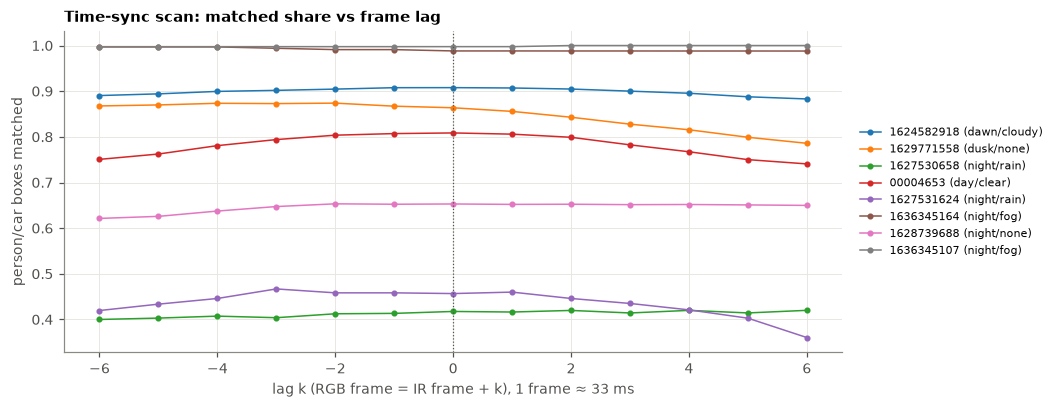

best lag per pair (share at best − share at lag 0):
  1624582918  +0  (+0.000)
  1629771558  -2  (+0.010)
  1627530658  +6  (+0.002)
  00004653    +0  (+0.000)
  1627531624  -3  (+0.010)
  1636345164  -4  (+0.009)
  1628739688  -2  (+0.000)
  1636345107  +2  (+0.002)


In [8]:
# Lag scan on every 2nd frame: IR frame i vs RGB frame i + lag of the same pair, map refitted at each lag (seeded from
# the lag-0 map), scored by the share of person/car boxes of both modalities matched one-to-one.
LAGS = np.arange(-6, 7)


def matched_share(pairs, P):
    n_m = n = 0
    for r, t in pairs:
        a, b = compare_pair(r, t, P)
        sr, st_ = np.isin(r.labels, FIT_CLASSES), np.isin(t.labels, FIT_CLASSES)
        n_m += (a[sr] == "matched").sum() + (b[st_] == "matched").sum()
        n += sr.sum() + st_.sum()
    return n_m / n if n else np.nan


lag_share = {}
for p in ORDER:
    rgb_at = {r.frame_index: r for r, _ in PAIR_FRAMES[p]}
    lag_share[p] = []
    for lag in LAGS:
        prs = [(rgb_at[t.frame_index + lag], t) for _, t in PAIR_FRAMES[p][::2] if t.frame_index + lag in rgb_at]
        lag_share[p].append(matched_share(prs, fit_mapping(prs, P0=MAP[p][0], gates=(0.05, 0.03))[0]))
    lag_share[p] = np.array(lag_share[p])

fig, ax = plt.subplots(figsize=(9.5, 3.6), constrained_layout=True)
cmap = plt.get_cmap("tab10")
for k, p in enumerate(ORDER):
    ax.plot(LAGS, lag_share[p], marker="o", ms=3, lw=1, color=cmap(k), label=f"{p} ({'/'.join(PAIR_CONDITIONS[p])})")
ax.axvline(0, color=MUTED, lw=0.8, ls=":")
ax.set_xlabel("lag k (RGB frame = IR frame + k), 1 frame ≈ 33 ms")
ax.set_ylabel("person/car boxes matched")
ax.set_title("Time-sync scan: matched share vs frame lag", loc="left")
ax.legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
plt.show()
print("best lag per pair (share at best − share at lag 0):")
for p in ORDER:
    b = int(np.nanargmax(lag_share[p]))
    print(f"  {p:<11} {LAGS[b]:+d}  (+{lag_share[p][b] - lag_share[p][LAGS == 0][0]:.3f})")

**Reading.** **The streams are in sync.** In every pair, the matched share at lag 0 is within 0.01 of the best lag in
−6…6.
- **Where the car moves, a lag costs matches.** `00004653` loses 0.06–0.07 at ±6 frames (0.2 s) and `1624582918`
  loses 0.02–0.03. Both peak exactly at 0.
- **`1629771558` (freeway) is the one open case.** Its curve is flat from −6 to 0 and drops by 0.08 at +6, so an RGB
  lead of 1–2 frames cannot be excluded. Its best lag (−2) gains only 0.010.
- **`1627530658` and `1627531624` have few boxes, so their curves are noisy.**

So `rgb_to_thermal_vid_map.json` pairs the same instants, to within a frame or two, and the disagreements in 2c do
not come from a time offset.

### 2e. Worst frames

Frames with the most `missing` boxes (empty frames excluded; at most one frame per second of a pair), to inspect in the viewer (§3): copy the pair and the
`frame_index` into the viewer cell.

In [9]:
worst = []
for p in ORDER:
    for r, t in PAIR_FRAMES[p]:
        sr, stt = STATUS["rgb", r.image_id], STATUS["thermal", t.image_id]
        if "empty frame" in sr or "empty frame" in stt:
            continue
        mr, mt = sr == "missing", stt == "missing"
        worst.append((mr.sum() + mt.sum(), p, r.frame_index, mr.sum(), mt.sum(),
                      Counter(CLASS_NAMES[c] for c in r.labels[mr]), Counter(CLASS_NAMES[c] for c in t.labels[mt])))
worst.sort(key=lambda w: -w[0])
# Neighbouring frames repeat the same scene: keep one frame per pair per 30 frames (≈ 1 s).
kept = []
for w in worst:
    if all(w[1] != k[1] or abs(w[2] - k[2]) >= 30 for k in kept):
        kept.append(w)
display(Markdown(md_table(
    ["pair", "frame_index", "RGB missing in IR", "IR missing in RGB", "RGB-only classes", "IR-only classes"],
    [[f"`{p}`", fi, a, b, ", ".join(f"{k} {v}" for k, v in ca.most_common()) or "–",
      ", ".join(f"{k} {v}" for k, v in cb.most_common()) or "–"] for _, p, fi, a, b, ca, cb in kept[:12]])))

| pair | frame_index | RGB missing in IR | IR missing in RGB | RGB-only classes | IR-only classes |
|---|---|---|---|---|---|
| `00004653` | 8041 | 32 | 1 | light 13, sign 10, car 9 | sign 1 |
| `1624582918` | 902 | 19 | 12 | light 9, sign 7, person 2, car 1 | sign 6, person 3, light 2, car 1 |
| `00004653` | 7822 | 27 | 4 | light 12, sign 10, car 4, person 1 | car 2, person 2 |
| `00004653` | 7881 | 30 | 1 | sign 13, light 10, car 7 | car 1 |
| `00004653` | 8006 | 29 | 1 | light 10, car 10, sign 8, person 1 | sign 1 |
| `1624582918` | 98 | 22 | 7 | light 11, sign 10, person 1 | person 5, car 2 |
| `1624582918` | 128 | 23 | 6 | light 11, sign 10, motor 2 | person 4, car 1, motor 1 |
| `1624582918` | 708 | 27 | 2 | sign 15, light 7, car 4, person 1 | sign 1, car 1 |
| `1624582918` | 214 | 23 | 5 | light 12, sign 4, person 3, bike 2, motor 1, car 1 | light 2, person 2, car 1 |
| `00004653` | 7914 | 25 | 3 | light 10, sign 9, car 6 | car 2, person 1 |
| `1624582918` | 1145 | 18 | 9 | sign 8, light 5, person 4, car 1 | person 6, car 2, motor 1 |
| `1624582918` | 33 | 22 | 4 | light 10, sign 9, motor 2, car 1 | car 4 |

## 3. Viewer: one frame pair, IR | RGB

Run the next cell once to list the videos, then set `VIDEO` in the cell after it (any of: the pair id, the RGB
`video_id` or the IR `video_id`) and run it again for a new random frame. `FRAME_INDEX` picks a specific frame
instead (e.g. from 2d), `SEED` repeats a draw.

Drawing: boxes of the 6 classes in the class colour with their name; **solid = matched** in the other modality,
**dashed = no counterpart** (the 2c status is appended to the name: `missing`, `border`, `swap`, `empty frame`);
grey dotted = ignore regions with their FLIR class. On RGB, the white dashed rectangle is the IR camera's view
(the 2b mapping).

In [10]:
print("VIDEOS = [")
for p in ORDER:
    vr, vt = PAIR_IDS[p]
    fr = [r.frame_index for r, _ in PAIR_FRAMES[p]]
    print(f'    "{p}",  # {"/".join(PAIR_CONDITIONS[p]):<12} {len(fr):>4} frames, frame_index {fr[0]}–{fr[-1]}, '
          f"RGB {vr}, IR {vt}")
print("]")

VIDEOS = [
    "1624582918",  # dawn/cloudy  1033 frames, frame_index 0–1479, RGB RMxN6a4CcCeLGu4tA, IR ZAtDSNuZZjkZFvMAo
    "1629771558",  # dusk/none     565 frames, frame_index 0–564, RGB dvZBYnphN2BwdMKBc, IR t3f7QC8hZr6zYXpEZ
    "1627530658",  # night/rain    540 frames, frame_index 300–839, RGB YnfPeH8i2uBWmsSd2, IR ePoikf5LyTTfqchga
    "00004653",  # day/clear     428 frames, frame_index 6393–8072, RGB msNEBxJE5PPDqenBM, IR SCiKdG3MqZfiE292B
    "1627531624",  # night/rain    411 frames, frame_index 99–509, RGB hnbGXq3nNPjBbc7CL, IR 5RSrbWYu9eokv5bvR
    "1636345164",  # night/fog     338 frames, frame_index 745–1082, RGB BzZspxAweF8AnKhWK, IR 4FRnNpmSmwktFJKjg
    "1628739688",  # night/none    226 frames, frame_index 0–225, RGB FkqCGijjAKpABetZZ, IR 6tLtjdkv5K5BuhB37
    "1636345107",  # night/fog     208 frames, frame_index 368–575, RGB PGdt7pJChnKoJDt35, IR vbrSzr4vFTm5QwuGH
]


pair 00004653 · time of day: day · weather: clear · frame_index 6426 (34 of 428 in this pair)

[IR] 00004653_cam1.zip (video_id SCiKdG3MqZfiE292B), image_id 1008, 640×512
  file: data/video-SCiKdG3MqZfiE292B-frame-006426-Zie9sSmbTJqMcjHj8.jpg
  video tags: adas, bridge, car, day, detroit, dualcapture, person, qa, stop sign, street sign, thermal, truck, seg, thermal
  description: DualCapture footage of the streets in and around Detroit. Captured in March 2019. Day 3
  qaStatus: – · isEmpty: False · isFlagged: False
  boxes: person 3, car 12, light 7, sign 4 · ignore: none
  vs other modality: matched 24, border 1, missing 1

[RGB] 00004653_cam2.avi (video_id msNEBxJE5PPDqenBM), image_id 3354, 1224×1024
  file: data/video-msNEBxJE5PPDqenBM-frame-006426-fSEG7J8WddurTT2p3.jpg
  video tags: adas, car, rgb, truck, bridge, street sign, person, backpack, stop sign, qa, dual capture, detroit, rgb
  description: Driving on the streets of Detroit.
  qaStatus: – · isEmpty: False · isFlagged: Fals

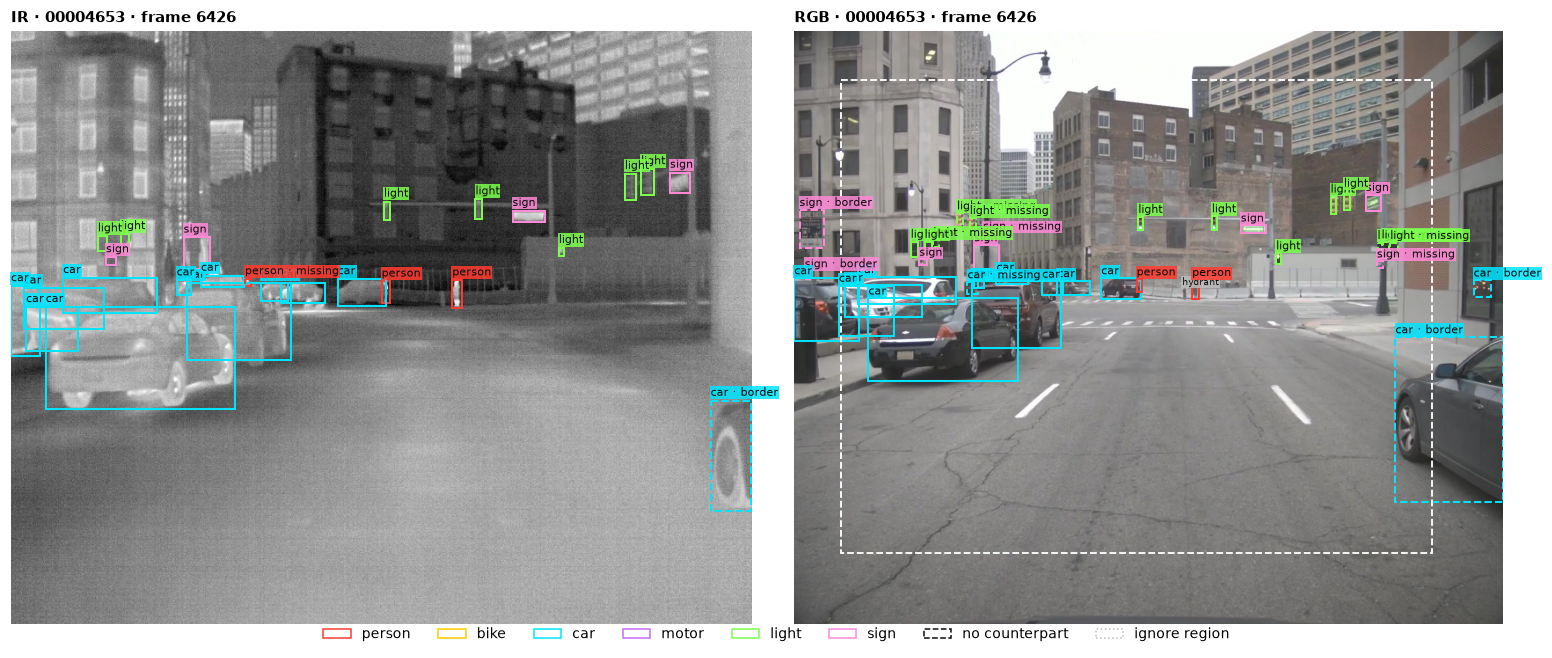

In [34]:
VIDEO = "00004653"  # pair id, RGB video_id or IR video_id (copy from the list above)
FRAME_INDEX = None    # None = random frame of the video; or a frame_index, e.g. from 2d
SEED = None           # an int repeats the same random frame
SHOW_IGNORE = True    # draw ignore regions (truck, bus, ...)

STATUS_TAG = {"matched": "", "class swap": " · swap", "border": " · border", "missing": " · missing",
              "empty frame": " · empty frame"}


def resolve_pair(video):
    for p, (vr, vt) in PAIR_IDS.items():
        if video in (p, vr, vt):
            return p
    raise KeyError(f"{video!r} is not a pair id, RGB video_id or IR video_id; pick one from the list above")


def draw(ax, x, statuses, fov=None):
    img = np.asarray(Image.open(x.path))
    ax.imshow(img, cmap="gray" if img.ndim == 2 else None, vmin=0, vmax=255)
    fs = 7
    if SHOW_IGNORE:
        for b, cid in zip(x.ignore_boxes, x.ignore_category_ids):
            ax.add_patch(Rectangle(b[:2], b[2], b[3], fill=False, ec=IGNORE_COLOR, lw=1, ls=":"))
            ax.text(b[0], b[1] - 2, CAT_NAME[int(cid)], color=INK, fontsize=fs - 1, va="bottom",
                    bbox=dict(fc=IGNORE_COLOR, ec="none", pad=0.6, alpha=0.85))
    for b, lab, s in zip(x.boxes, x.labels, statuses):
        col = CLASS_COLOR[CLASS_NAMES[lab]]
        ax.add_patch(Rectangle(b[:2], b[2], b[3], fill=False, ec=col, lw=1.3, ls="-" if s == "matched" else "--"))
        ax.text(b[0], b[1] - 2, CLASS_NAMES[lab] + STATUS_TAG[s], color=INK, fontsize=fs, va="bottom",
                bbox=dict(fc=col, ec="none", pad=0.6, alpha=0.85))
    if fov is not None:
        ax.add_patch(Rectangle(fov[:2], fov[2] - fov[0], fov[3] - fov[1], fill=False, ec="white", lw=1.2, ls="--"))
    ax.set_xlim(0, x.width)
    ax.set_ylim(x.height, 0)
    ax.axis("off")


def show_pair(video, frame_index=None, seed=None):
    p = resolve_pair(video)
    frames = PAIR_FRAMES[p]
    if frame_index is None:
        r, t = frames[np.random.default_rng(seed).integers(len(frames))]
    else:
        match = [pair for pair in frames if pair[0].frame_index == frame_index]
        if not match:
            raise KeyError(f"frame_index {frame_index} not in pair {p} ({frames[0][0].frame_index}–"
                           f"{frames[-1][0].frame_index}, gaps possible)")
        r, t = match[0]
    P = MAP[p][0]
    st = {"rgb": STATUS["rgb", r.image_id], "thermal": STATUS["thermal", t.image_id]}

    # Metadata, printed above the figure.
    time, weather = PAIR_CONDITIONS[p]
    print(f"pair {p} · time of day: {time} · weather: {weather} · frame_index {r.frame_index} "
          f"({frames.index((r, t)) + 1} of {len(frames)} in this pair)")
    for m, x in [("thermal", t), ("rgb", r)]:
        v = VIDEO_META[m][x.video_id]
        f = FRAME_META[m][uid(x.file_name)]
        cnt = Counter(CLASS_NAMES[c] for c in x.labels)
        sc = Counter(st[m])
        print(f"\n[{MOD_LABEL[m]}] {v['filename']} (video_id {x.video_id}), image_id {x.image_id}, "
              f"{x.width}×{x.height}")
        print(f"  file: {x.file_name}")
        print(f"  video tags: {', '.join(v['tags'])}")
        if v.get("description"):
            print(f"  description: {' '.join(v['description'].split())}")
        print(f"  qaStatus: {f.get('qaStatus', '–')} · isEmpty: {f['isEmpty']} · isFlagged: {f['isFlagged']}")
        print(f"  boxes: {', '.join(f'{c} {cnt[c]}' for c in CLASS_NAMES if cnt[c]) or 'none'}"
              f" · ignore: {', '.join(f'{CAT_NAME[k]} {n}' for k, n in Counter(map(int, x.ignore_category_ids)).items()) or 'none'}")
        print(f"  vs other modality: {', '.join(f'{s} {sc[s]}' for s in STATUSES if sc[s]) or '–'}")

    fov = np.array([P[1], P[3], P[0] + P[1], P[2] + P[3]]) * np.array([r.width, r.height] * 2)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), constrained_layout=True,
                             gridspec_kw=dict(width_ratios=[t.width / t.height, r.width / r.height]))
    draw(axes[0], t, st["thermal"])
    draw(axes[1], r, st["rgb"], fov=fov)
    axes[0].set_title(f"IR · {p} · frame {t.frame_index}", loc="left")
    axes[1].set_title(f"RGB · {p} · frame {r.frame_index}", loc="left")
    handles = [Patch(fc="none", ec=CLASS_COLOR[c], label=c) for c in CLASS_NAMES]
    handles += [Patch(fc="none", ec=INK, ls="--", label="no counterpart"),
                Patch(fc="none", ec=IGNORE_COLOR, ls=":", label="ignore region")]
    fig.legend(handles=handles, loc="lower center", ncol=len(handles), bbox_to_anchor=(0.5, -0.04))
    plt.show()


show_pair(VIDEO, FRAME_INDEX, SEED)